# 04 — Les données en tokens : TinyStories et tiktoken

Le modèle caractère des notebooks 02 et 03 a appris la **forme** d'une
comptine, pas le **sens**, et il reprend mal les mots-clés. Deux causes :

- **trop peu de texte** : 400 000 caractères ne suffisent pas pour apprendre
  l'anglais ;
- **des mots à épeler** : pour reprendre `moon`, il doit écrire `m`, `o`,
  `o`, `n` au bon moment en se souvenant de la consigne.

La suite du projet (voir `PLAN.md`) répond aux deux :

1. **pré-entraîner** sur **TinyStories**, des dizaines de milliers d'histoires
   en anglais très simple, puis **fine-tuner** sur les comptines ;
2. passer à la **tokenisation BPE** de GPT-2 avec `tiktoken` (notebook 08 du
   cours) : `moon` devient un seul token.

Ce notebook prépare les données : il télécharge un extrait de TinyStories,
le tokenise avec `tiktoken`, construit un vocabulaire réduit, et sauvegarde
tout sous forme de tokens pour l'entraînement (notebook 05).

In [1]:
import json
import random
import unicodedata
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import tiktoken
import torch

from comptines import BPETokenizer, content_words, make_prompt

In [2]:
SEED = 1337
random.seed(SEED)

try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
BPE_DIR = DATA_DIR / "bpe"
TINYSTORIES_URL = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/{name}"

# Fichier → nombre de Mo qu'on en télécharge.
EXTRACTS = {
    "TinyStoriesV2-GPT4-train.txt": 50,
    "TinyStoriesV2-GPT4-valid.txt": 5,
}

## 1. Télécharger un extrait de TinyStories

**TinyStories** (Eldan et Li, 2023) : des histoires courtes écrites par GPT-4
avec le vocabulaire d'un enfant de 3-4 ans. Les auteurs l'ont construit pour
montrer qu'un modèle de **quelques millions de paramètres** (TinyStories-8M,
de la taille du nôtre) peut écrire des histoires cohérentes, à condition que
le texte soit simple.

Le fichier d'entraînement fait 2,2 Go : bien plus que ce qu'on peut
exploiter en une heure sur une RTX 3050. On n'en télécharge que le début
grâce à une **requête HTTP partielle** (en-tête `Range: bytes=0-...`) : le
serveur n'envoie que les octets demandés.

In [3]:
RAW_DIR.mkdir(parents=True, exist_ok=True)
paths = {}
for name, megabytes in EXTRACTS.items():
    path = RAW_DIR / name.replace(".txt", f".{megabytes}MB.txt")
    if not path.exists():
        request = urllib.request.Request(TINYSTORIES_URL.format(name=name),
                                         headers={"Range": f"bytes=0-{megabytes * 2**20 - 1}"})
        with urllib.request.urlopen(request) as response:
            path.write_bytes(response.read())
    paths[name] = path
    print(f"{path.name:40} {path.stat().st_size / 2**20:.0f} Mo")

TinyStoriesV2-GPT4-train.50MB.txt        50 Mo
TinyStoriesV2-GPT4-valid.5MB.txt         5 Mo


## 2. Découper et nettoyer

Dans le fichier, les histoires sont séparées par le texte `<|endoftext|>`.
On découpe dessus, et on jette la **dernière** histoire : la coupure à
50 Mo l'a tranchée au milieu (et peut-être au milieu d'un caractère UTF-8,
d'où `errors="ignore"`).

Regardons les caractères hors ASCII :

In [4]:
def read_stories(path: Path) -> list[str]:
    """Les histoires complètes d'un extrait (la dernière, coupée, est jetée)."""
    text = path.read_bytes().decode("utf-8", errors="ignore")
    return [s.strip() for s in text.split("<|endoftext|>")[:-1] if s.strip()]


raw_train = read_stories(paths["TinyStoriesV2-GPT4-train.txt"])
raw_val = read_stories(paths["TinyStoriesV2-GPT4-valid.txt"])
print(f"{len(raw_train):,} histoires d'entraînement   {len(raw_val):,} de validation\n")

for ch, n in Counter(c for s in raw_train for c in s if ord(c) > 127).most_common(10):
    print(f"{n:>6}  U+{ord(ch):04X}  {unicodedata.name(ch, '?')}")

63,936 histoires d'entraînement   6,457 de validation



  3823  U+201C  LEFT DOUBLE QUOTATION MARK
  3809  U+201D  RIGHT DOUBLE QUOTATION MARK
  2814  U+2019  RIGHT SINGLE QUOTATION MARK
   152  U+2013  EN DASH
    58  U+2014  EM DASH
    49  U+2018  LEFT SINGLE QUOTATION MARK
    21  U+2026  HORIZONTAL ELLIPSIS
     5  U+00E9  LATIN SMALL LETTER E WITH ACUTE
     4  U+00F1  LATIN SMALL LETTER N WITH TILDE
     3  U+00A0  NO-BREAK SPACE


Surtout de la typographie : guillemets courbes, apostrophe courbe,
points de suspension. Même traitement qu'au notebook 01 : on ramène à
l'ASCII. Le BPE de GPT-2 saurait les encoder, mais `’` et `'` seraient deux
tokens différents pour le même sens. On écarte les rares histoires où il
reste autre chose.

In [5]:
TYPO = {"’": "'", "‘": "'", "“": '"', "”": '"', "—": "--", "–": "-",
        "…": "...", " ": " ", "​": ""}


def clean(story: str) -> str:
    """Ramène la typographie à l'ASCII."""
    for fancy, plain in TYPO.items():
        story = story.replace(fancy, plain)
    return story


def clean_all(stories: list[str]) -> list[str]:
    """Nettoie, et écarte les histoires qui gardent des caractères hors ASCII."""
    return [s for s in map(clean, stories) if s.isascii()]


train_stories, val_stories = clean_all(raw_train), clean_all(raw_val)
print(f"gardées : {len(train_stories):,} / {len(raw_train):,} (train)   {len(val_stories):,} / {len(raw_val):,} (val)\n")
print(train_stories[0])

gardées : 63,929 / 63,936 (train)   6,457 / 6,457 (val)

Once upon a time there was a little boy named Ben. Ben loved to explore the world around him. He saw many amazing things, like beautiful vases that were on display in a store. One day, Ben was walking through the store when he came across a very special vase. When Ben saw it he was amazed!  
He said, "Wow, that is a really amazing vase! Can I buy it?" 
The shopkeeper smiled and said, "Of course you can. You can take it home and show all your friends how amazing it is!"
So Ben took the vase home and he was so proud of it! He called his friends over and showed them the amazing vase. All his friends thought the vase was beautiful and couldn't believe how lucky Ben was. 
And that's how Ben found an amazing vase in the store!


## 3. Le découpage de GPT-2 avec `tiktoken`

Rappel du notebook 08 : le **BPE** part des octets et fusionne, encore et
encore, les paires les plus fréquentes. Les mots courants finissent en **un
seul token**, souvent avec l'espace qui les précède (` cat`), et les mots
rares en plusieurs morceaux. `tiktoken` fournit le tokenizer exact de GPT-2 :
50 257 tokens, dont le token spécial `<|endoftext|>`.

In [6]:
enc = tiktoken.get_encoding("gpt2")
sentence = "Once upon a time, a little cat jumped over the moon."
tokens = enc.encode_ordinary(sentence)
print(f"{len(sentence)} caractères → {len(tokens)} tokens")
print([enc.decode([t]) for t in tokens])
print(f"\n<|endoftext|> : token {enc.eot_token}   vocabulaire GPT-2 : {enc.n_vocab:,} tokens")

52 caractères → 13 tokens
['Once', ' upon', ' a', ' time', ',', ' a', ' little', ' cat', ' jumped', ' over', ' the', ' moon', '.']

<|endoftext|> : token 50256   vocabulaire GPT-2 : 50,257 tokens


`encode_ordinary` ignore les tokens spéciaux : un `<|endoftext|>` écrit
dans le texte serait découpé comme du texte ordinaire. On ajoutera le vrai
token de fin nous-mêmes, à la fin de chaque exemple.

On tokenise tout le corpus (`encode_ordinary_batch` répartit le travail sur
plusieurs cœurs) :

In [7]:
train_tokens = enc.encode_ordinary_batch(train_stories)
val_tokens = enc.encode_ordinary_batch(val_stories)
n_chars = sum(len(s) for s in train_stories)
n_tokens = sum(len(t) for t in train_tokens)
print(f"train : {n_chars:,} caractères → {n_tokens:,} tokens   ({n_chars / n_tokens:.2f} caractères par token)")

train : 51,416,437 caractères → 12,662,874 tokens   (4.06 caractères par token)


Environ **4 caractères par token** : à fenêtre égale, le modèle voit 4 fois
plus de texte qu'un modèle caractère. Une fenêtre de 256 tokens couvre
environ 1 000 caractères.

### Les mots-clés deviennent des tokens

C'est ce qui compte pour notre consigne. Dans `words: cat, moon`, chaque mot
est précédé d'une espace, comme au milieu d'une phrase : si ` moon` est un
seul token, reprendre le mot-clé revient à **recopier un token** déjà présent
dans la consigne, ce que l'attention sait très bien faire. Combien de nos
mots-clés sont dans ce cas ?

In [8]:
def single_token_rate(texts: list[str]) -> float:
    """Part des mots-clés possibles (content_words) qui tiennent en un seul token GPT-2."""
    words = Counter(w for t in texts for w in content_words(t))
    single = sum(n for w, n in words.items() if len(enc.encode_ordinary(" " + w)) == 1)
    return single / sum(words.values())


rhymes_train = (DATA_DIR / "comptines_train.txt").read_text(encoding="utf-8").split("\n\n")
rhymes_val = (DATA_DIR / "comptines_val.txt").read_text(encoding="utf-8").split("\n\n")
print(f"mots-clés d'un seul token : {single_token_rate(train_stories[:5_000]):.1%} (TinyStories)   "
      f"{single_token_rate(rhymes_train):.1%} (comptines)")

mots-clés d'un seul token : 97.1% (TinyStories)   80.1% (comptines)


## 4. La longueur des exemples et `block_size`

Comme au notebook 02, le modèle doit voir **la consigne et tout le texte**
dans la même fenêtre. Mesurons les histoires en tokens :

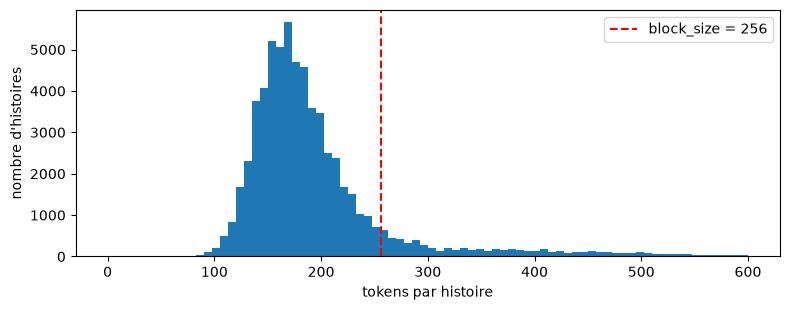

histoires de 128 tokens ou moins : 5.7%
histoires de 192 tokens ou moins : 64.7%
histoires de 256 tokens ou moins : 88.7%
histoires de 384 tokens ou moins : 95.4%


In [9]:
lengths = [len(t) for t in train_tokens]
block_size = 256
plt.figure(figsize=(8, 3.2))
plt.hist(lengths, bins=80, range=(0, 600))
plt.axvline(block_size, color="red", linestyle="--", label=f"block_size = {block_size}")
plt.xlabel("tokens par histoire")
plt.ylabel("nombre d'histoires")
plt.legend()
plt.tight_layout()
plt.show()
for b in [128, 192, 256, 384]:
    print(f"histoires de {b} tokens ou moins : {sum(n <= b for n in lengths) / len(lengths):.1%}")

On garde `block_size = 256`. Le coût de l'attention croît comme le **carré**
de la fenêtre : passer à 384 coûterait plus du double, sur une carte de 4 Go,
pour seulement quelques pourcents d'histoires en plus.

Que faire des histoires trop longues ? Au notebook 02, on coupait les rares
comptines trop longues. Ici, une histoire coupée perdrait sa fin et son
`<|endoftext|>` : le modèle apprendrait des histoires qui ne finissent pas. On
a assez de données pour se permettre de les **écarter**. On garde une marge
pour la consigne (au plus 16 tokens) et le token de fin.

In [10]:
MAX_PROMPT_TOKENS = 16
max_story_tokens = block_size - MAX_PROMPT_TOKENS - 1  # - 1 : le token <|endoftext|>


def keep_short(stories: list[str], tokens: list[list[int]]) -> tuple[list[str], list[list[int]]]:
    """Garde les histoires qui tiennent dans la fenêtre avec leur consigne."""
    kept = [(s, t) for s, t in zip(stories, tokens) if len(t) <= max_story_tokens]
    return [s for s, _ in kept], [t for _, t in kept]


train_stories, train_tokens = keep_short(train_stories, train_tokens)
val_stories, val_tokens = keep_short(val_stories, val_tokens)
print(f"gardées : {len(train_stories):,} histoires d'entraînement ({sum(map(len, train_tokens)):,} tokens)   "
      f"{len(val_stories):,} de validation")

gardées : 54,849 histoires d'entraînement (9,396,491 tokens)   5,594 de validation


## 5. Un vocabulaire réduit

Le vocabulaire de GPT-2 a 50 257 tokens, pensés pour tout Internet : du
code, des noms propres, d'autres langues. Nos histoires pour enfants n'en
utilisent qu'une petite partie.

Pourquoi c'est important : la table d'embedding et la couche de sortie ont
une ligne **par token**. La couche de sortie calcule un logit pour chacun des
tokens, à chaque position de chaque exemple du lot : avec 50 257 tokens, les
logits d'un seul lot de 16 × 256 positions pèsent 800 Mo, sans compter leurs
gradients. Trop pour une carte de 4 Go.

On garde donc **le découpage de GPT-2**, mais seulement les tokens qui
apparaissent dans nos données d'**entraînement** (TinyStories et comptines),
renumérotés de 0 à `vocab_size - 1`. On y ajoute :

- `<|endoftext|>`, notre token de fin ;
- les **256 tokens d'un octet** (`a`, `b`, `,`…). Un token jamais vu (dans
  un mot-clé exotique ou dans la validation) peut toujours s'écrire octet par
  octet : rien n'est impossible à encoder.

In [11]:
rhyme_tokens_train = enc.encode_ordinary_batch(rhymes_train)
prompt_tokens = enc.encode_ordinary("words: cat, moon\n")  # les tokens de la consigne

seen = Counter(t for toks in train_tokens + rhyme_tokens_train for t in toks)
gpt2_ids = sorted(set(seen) | set(prompt_tokens) | set(range(256)) | {enc.eot_token})
print(f"vocabulaire réduit : {len(gpt2_ids):,} tokens au lieu de {enc.n_vocab:,}")
print(f"dont vus au moins 5 fois : {sum(n >= 5 for n in seen.values()):,}")

vocabulaire réduit : 14,122 tokens au lieu de 50,257
dont vus au moins 5 fois : 8,333


La classe `BPETokenizer` du module `comptines.py` fait la traduction. Le
cœur de `encode` :

```python
for t in self.enc.encode_ordinary(s):        # découpage GPT-2
    if t in self.to_compact:
        ids.append(self.to_compact[t])       # identifiant GPT-2 → indice compact
    else:                                    # token jamais vu : octet par octet
        ids.extend(self.byte_ids[b] for b in self.enc.decode_single_token_bytes(t))
```

Vérifions qu'on retrouve bien le texte, y compris avec des mots que les
histoires pour enfants ne contiennent sans doute pas :

In [12]:
tokenizer = BPETokenizer(gpt2_ids)
for text in ["words: cat, moon\nThe little cat looked at the moon.", "words: photosynthesis, Kubernetes"]:
    ids = tokenizer.encode(text)
    assert tokenizer.decode(ids) == text
    print(f"{len(ids):>3} tokens : {[tokenizer.decode([i]) for i in ids]}")

 14 tokens : ['words', ':', ' cat', ',', ' moon', '\n', 'The', ' little', ' cat', ' looked', ' at', ' the', ' moon', '.']
 18 tokens : ['words', ':', ' photos', 'y', 'n', 't', 'h', 'e', 's', 'i', 's', ',', ' ', 'K', 'u', 'ber', 'net', 'es']


Combien de tokens de la **validation** manquent au vocabulaire ? Ils
n'empêchent rien (ils seront écrits octet par octet), mais il faut qu'ils
soient rares.

In [13]:
vocab = set(gpt2_ids)
missing = sum(t not in vocab for toks in val_tokens for t in toks)
print(f"tokens de validation hors vocabulaire : {missing:,} sur {sum(map(len, val_tokens)):,} "
      f"({missing / sum(map(len, val_tokens)):.3%})")

tokens de validation hors vocabulaire : 459 sur 956,938 (0.048%)


## 6. Le format d'un exemple

Le même qu'aux notebooks 01 et 02, avec le token `<|endoftext|>` à la place
de la ligne vide :

```
words: cat, moon
Once upon a time, a little cat ...<|endoftext|>
```

Les mots-clés sont les **mots porteurs de sens** du texte (même fonction
`content_words`), tirés à nouveau à chaque passage pendant l'entraînement
(notebook 05). On stocke donc, pour chaque histoire, ses tokens et la liste
des mots-clés possibles ; la consigne sera construite au moment de
l'entraînement.

In [14]:
story = train_stories[3]
keywords = random.sample(content_words(story), 3)
example = tokenizer.encode(make_prompt(keywords) + story) + [tokenizer.eot]
print(f"mots-clés possibles : {content_words(story)[:15]} ...\n")
print(repr(tokenizer.decode(example)[:300]), "...\n")
print(f"{len(example)} tokens, dont {len(tokenizer.encode(make_prompt(keywords)))} pour la consigne")

mots-clés possibles : ['time', 'friendly', 'little', 'boy', 'called', 'bob', 'loved', 'pick', 'flowers', 'look', 'birds', 'day', 'decided', 'outside', 'friends'] ...

'words: appreciation, happily, curiously\nOnce upon a time there was a friendly little boy called Bob. Bob loved to pick flowers and look for birds. One day he decided to go outside with his friends to pick some more flowers. \nHe suddenly noticed something weird on the ground. It was a big, green thum' ...

200 tokens, dont 8 pour la consigne


## 7. Sauvegarder

Pour chaque corpus (histoires et comptines, train et validation) :

- `ids` : tous les tokens (indices compacts), mis bout à bout dans un seul
  tenseur ;
- `offsets` : où commence chaque texte dans `ids` (le texte `i` va de
  `offsets[i]` à `offsets[i + 1]`) ;
- `keywords` : les mots-clés possibles de chaque texte.

Un seul grand tenseur plutôt qu'une liste de 50 000 petits : plus compact, et
plus rapide à recharger. Le vocabulaire (la liste `gpt2_ids`) est sauvegardé
à part, en JSON.

In [15]:
def pack(texts: list[str]) -> dict:
    """Tokenise des textes et les range en `ids` / `offsets` / `keywords`."""
    encoded = [tokenizer.encode(t) for t in texts]
    offsets = torch.tensor([0] + [len(e) for e in encoded]).cumsum(0)
    ids = torch.tensor([i for e in encoded for i in e], dtype=torch.int32)
    return {"ids": ids, "offsets": offsets, "keywords": [content_words(t) for t in texts]}


BPE_DIR.mkdir(parents=True, exist_ok=True)
(BPE_DIR / "vocab.json").write_text(json.dumps(gpt2_ids))
corpora = {"tinystories_train": train_stories, "tinystories_val": val_stories,
           "comptines_train": rhymes_train, "comptines_val": rhymes_val}
for name, texts in corpora.items():
    packed = pack(texts)
    torch.save(packed, BPE_DIR / f"{name}.pt")
    print(f"{name:18} {len(texts):>7,} textes   {len(packed['ids']):>11,} tokens   → {(BPE_DIR / f'{name}.pt').relative_to(ROOT)}")

tinystories_train   54,849 textes     9,396,491 tokens   → data\bpe\tinystories_train.pt


tinystories_val      5,594 textes       959,248 tokens   → data\bpe\tinystories_val.pt


comptines_train      2,682 textes       110,534 tokens   → data\bpe\comptines_train.pt
comptines_val          299 textes        13,198 tokens   → data\bpe\comptines_val.pt


Pour relire un texte : `tokenizer.decode(ids[offsets[i]:offsets[i + 1]].tolist())`.
Le notebook 05 recharge ces fichiers et `vocab.json` pour reconstruire le
même `BPETokenizer`.